# Where is the headroom over EI? Basin decomposition of static arms and luck-corrected option labels

## Description

<!-- Written 2026-11-12 before the first run (pre-registration). Design: research_log/decisions/0008 (shared reasoning with Tim). Issue #13. -->

**Question.** Two rounds of candidate-level policy improvement found no advantage over EI (api_round1, api_decoder). Decision 0008 traced this to four causes:
- a linear reward;
- label noise from our own stochastic EI;
- log regret mixing basin discovery with polishing;
- one-step deviations that the horizon washes out.

Luck-corrected switching headroom does exist with task knowledge: BBOB +66% at d = 2 (decided); the prior pilot +37%, indicative only.

This experiment asks, with exact and luck-corrected labels: **is there an advantage over EI in following a different acquisition rule for k steps, and does it come from finding the right basin?** It is the signal any policy improvement needs, measured before any learning.

**Setup** (`experimental/options.py`, `tasks/option_headroom.py`). d = 2, n_init = 4, T = 20, pfn_large, fp32.
- *Deterministic arms.* Every arm maximizes its acquisition over a candidate set that depends only on the data and a seed s: a scrambled Sobol set (1024 points) plus fixed perturbations of the incumbent (64 at each of σ = 0.01, 0.05, 0.2).
  - For a fixed s, every policy is deterministic. The tasks are noise-free, so one continuation is an exact outcome.
  - Two seeds, s ∈ {0, 1}, are two equally uninformed candidate sets. They are the **luck replicates**.
  - Arms: EI, PI(ξ = 0.01), UCB(0.995), MES, posterior mean (static_tune's portfolio without ES).
- *Reward.* Terminal log10 regret, log10(best − f\* + ε) with ε = 1e-7 (BO standard).
  - f\* comes from the strong search (16384 Sobol points plus 16×200 Adam steps), lowered by every run.
  - A 16× stronger search never improved f\* by more than 1e-6 at d = 2 (track record 2026-11-12).
- *Basins (privileged, diagnostic only).*
  - Projected Adam descent on the true f (300 steps, lr 0.003) from an incumbent gives the value of the basin it drains to.
  - "Good basin" = within δ ∈ {1, 10} PFN bins (0.001) of f\*.
  - A second setting (600 steps, lr 0.001) checks the label's robustness.
- *Part A* (split 0, 500 tasks): full runs of every arm under both seeds. Per step: the regret, and whether the incumbent is in a good basin.
- *Part B* (split 4, 800 fresh tasks, task offset 20000):
  - **Branch state:** one per task, by EI (seed 0) to a step t drawn uniformly from 0–15.
  - **Base:** EI to T.
  - **Options:** each of PI, UCB, MES and mean for k ∈ {1, 3, 5} steps, then EI to T.
  - **Nulls:** `ei@j`, j ∈ {0, 1}, = EI over a fixed random half of the candidates for k steps. Same kind of deviation, no information.
  - Everything runs under both seeds; the advantage of option o under seed s is log10 R_T(base, s) − log10 R_T(o, s), positive = better.
  - Per lane, also recorded:
    - whether the first pick differs from EI's;
    - the final incumbent's basin;
    - the belief after the option: P(y(x\*) < state incumbent) and the distance from the belief's predicted minimum to x\*.

**What to look for.**
1. **Primary** (Part B): the cross-fitted headroom H₃ of the arms.
   - Per state, choose the option with the best advantage on one seed, or none if no advantage is > 0.
   - Score that choice on the other seed, average both directions, then average over states, with a bootstrap CI over states.
   - An option that is best only by luck of the candidate set does not transfer across seeds.
2. Secondary (Part B):
   - H₁ and H₅;
   - the same for the null family, and arms − nulls: the luck scale and the luck-corrected contrast;
   - the in-sample best (oracle), biased upwards, for scale;
   - per option: the mean advantage, the share that disagree with EI, the net basin gain (P(option ends in a good basin while EI does not) − the reverse), and the belief measures against the nulls at the same k;
   - everything by t.
3. Part A (descriptive):
   - P(good basin by t) per arm and seed;
   - log-regret curves per arm;
   - how much of the differences between arms is basin discovery (the regret given a good basin vs the share in a good basin);
   - seed-to-seed spread as the luck scale.

**GO / NO-GO** (rule `analysis/options.py::option_verdict`, on the arms' H₃; worthwhile = 0.022 log10, i.e. 5% less regret).
- **GO**: the CI of H₃ is above 0 and H₃ ≥ 0.022. There is a luck-corrected, exploitable advantage over EI in switching for 3 steps. Next: can the belief find it (0008 §4 step 3)?
- **NO-GO**: the upper CI bound of H₃ is < 0.022. Even with task knowledge, 3-step switching does not beat EI beyond luck on this prior at d = 2. Next: higher d, or longer options.
- **INCONCLUSIVE**: otherwise.

**Limits.**
- Noise-free P0, d = 2, T = 20 only; d = 2 is mostly solved by EI (0007).
- Two seeds make a coarse luck correction. Cross-fitting removes selection bias, but an option whose advantage depends on the candidate set itself counts as luck.
- One branch state per task.
- Basin labels by local descent can mislead (near-equal optima, valleys from irrelevant dimensions, plateaus; 0008 §3). They are a diagnostic, never the reward.
- The headroom is privileged: an upper bound on what a belief-based switching policy can reach, not a policy.


### Revision after the sanity run (2026-11-12, before the pilot)

Sanity: `results/option_headroom/sanity_20261112-110719`, 50 + 60 tasks, 3 min. The pipeline works, and the two descent settings agree on the basin label for 100% of tasks. Two changes before the pilot; the primary quantity and rule are unchanged:
1. **ε = 1e-6 instead of 1e-7.**
   - f\* is lowered by our own runs, so the lane that found the lowest value has regret exactly 0 and log10 regret = log10 ε. This affected 9% of Part A and 14% of Part B regrets.
   - With ε = 1e-7, below f\*'s accuracy of about 1e-6 (strong-search check, track record 2026-11-12), that produces artificial advantages of up to several decades.
   - Robustness at ε = 1e-5 is recomputed from the raw regrets in the analysis.
2. **A static comparator** (secondary, key for interpretation).
   - Part A suggests UCB(0.995) and MES polish better than EI on log regret. Every arm's mean advantage over EI was positive in sanity, so part of H is a *static* improvement (always switch to one arm), not a context-dependent one.
   - New rows in `headroom`:
     - `static`: the best single option, chosen by its mean advantage on one seed and scored on the other;
     - `arms-static`: the context-dependent part, H − H_static, with a paired bootstrap CI over states.
   - Reading:
     - GO with arms − static > 0 (CI) → context-dependent switching has value beyond the best static switch;
     - GO with arms − static ≈ 0 → the headroom is mostly "a better static arm than EI under log regret".

Also observed in sanity, which affects interpretation, not the design: the median τ (first step in a good basin, δ = 1 bin) is 0 for every arm. Local descent from the initial incumbent already reaches a good basin in most d = 2 tasks. So at d = 2 the differences between arms are mostly *polishing*, not basin discovery (0008 §3 anticipated this).


### Addendum before the d = 4 sweep (2026-11-13)

Written before the run. With Tim, 2026-11-13: go to harder problems. At d = 2 nearly every run finds the global basin at once, 80% of EI runs end below one PFN bin (1e-3), and the headroom is mostly polishing (observations above; notebooks 13 and 15). **Is that different at d = 4?** The same pipeline, one member with `task.d=4` (n_init = 8, T = 40, contexts ≤ 48; `part_b.t_max=30`), nothing else changed.

What to look for, beside the quantities above:
- Part A: where the arms' regret sits relative to one PFN bin, along the run (share of runs above 1e-3 and 1e-2 at T/4, T/2, T); the share of runs in a good basin over time and the time to a good basin (at d = 2 the median was 0); which static arm is best at T/2 and at T.
- Part B: the option headroom H₃ and its static and context-dependent parts; the net basin gain of options; all also at ε = 1e-3 (the floor at the belief's resolution), from the stored raw regrets.

No new GO / NO-GO rule: the pre-registered rule above is evaluated for d = 4 as it was for d = 2. Reading for the next step: if most runs still end below one bin and options change basins as rarely as at d = 2, d = 4 with this budget is not the harder regime either, and the budget has to shrink or d to grow.

Limit added at d = 4: f\* comes from 16384 Sobol points plus refinement, which is coarser in 4-D; it is lowered by every run's best value, and regrets below about 1e-4 should be read with that in mind.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.options import crossfit_table, option_verdict, with_eps

SNAPSHOT = "results/option_headroom/pilot_20261112-111235"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot
cfg = snap.config["task"] if hasattr(snap, "config") else None

## How it was run

```bash
just sweep detached pilot experiment=option_headroom task.d=2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261112-111235` |
| commit | `190c3a11d18b` (tag `sweep/option_headroom/pilot_20261112-111235`) |
| backend / host | detached / ulysses |
| ran | 2026-11-12T11:12:37 → 2026-11-12T11:38:17 |
| members | 1: 1 done |
| compute | 25.7 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/option_headroom.yaml`):

```yaml
# @package _global_
# Basin decomposition of static arms and exact, luck-corrected option labels (issue #13, decision 0008).
# Pre-registration: notebooks/12_2026-11-12_option_headroom.ipynb.
defaults:
  - override /task: option_headroom

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  arms: '["ei", "pi0.01", "ucb0.995", "mes", "mean"]'
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  deltas: '[1, 10]'
  descent.check_lr: 0.001
  descent.check_steps: 600
  descent.chunk: 65536
  descent.lr: 0.003
  descent.steps: 300
  device: cuda
  eps: 1.0e-06
  ks: '[1, 3, 5]'
  n_boot: 2000
  n_init_per_d: 2
  n_null: 2
  name: option_headroom
  part_a.n_tasks: 500
  part_a.split: 0
  part_a.task_offset: 0
  part_b.n_tasks: 800
  part_b.split: 4
  part_b.t_max: 15
  part_b.task_offset: 20000
  pfn: pfn_large
  primary_k: 3
  seeds: '[0, 1]'
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  tf32: false
  worthwhile_log10: 0.022
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
print("minutes:", {k: round(float(S[k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
A, B, head, arms_b, chk = (snap.table(k) for k in ("part_a", "part_b", "headroom", "arms_b", "descent_check"))
print("Part A tasks:", A.task.nunique(), "| arms:", sorted(A.arm.unique()), "| seeds:", sorted(A.rep.unique()))
print("Part B states:", B.state.nunique(), "| options:", B.option.nunique(), "| lanes:", len(B))
print("basin label robustness (agreement of two descent settings):"); display(chk)
floor = (A.regret_bins == 0).mean(), (B.regret_bins == 0).mean()
print(f"share of regrets at the eps floor (exactly f*): Part A {floor[0]:.3f}, Part B {floor[1]:.3f}")

member status: {'DONE': 1}
minutes: {'time/part_a_s': 7.3, 'time/part_b_s': 18.3}
Part A tasks: 500 | arms: ['ei', 'mean', 'mes', 'pi0.01', 'ucb0.995'] | seeds: [np.int64(0), np.int64(1)]
Part B states: 800 | options: 19 | lanes: 30400
basin label robustness (agreement of two descent settings):


,delta_bins,agree,member
0,1.0,1.0,0
1,10.0,1.0,0


share of regrets at the eps floor (exactly f*): Part A 0.072, Part B 0.097


## 1. Part A: static arms, regret and basin discovery (split 0)

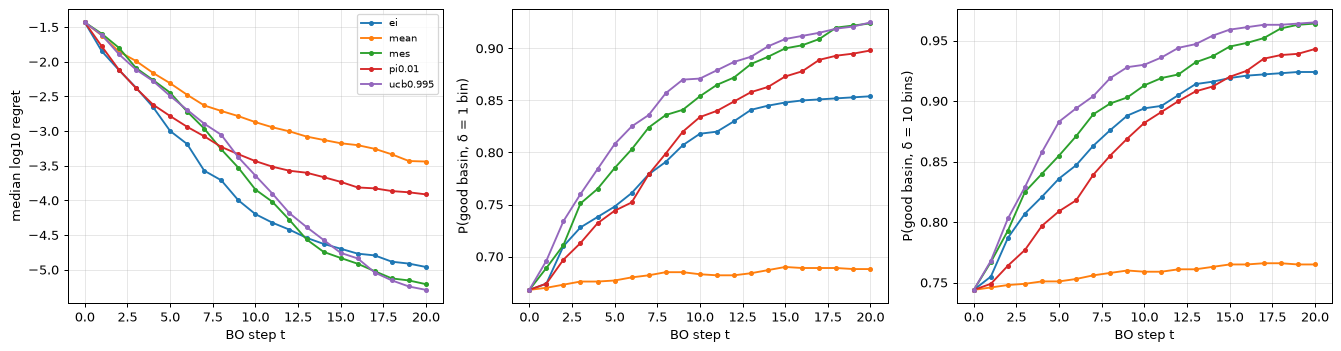

final step, per arm (both seeds pooled):


,log_regret_mean,log_regret_median,good1_T,good10_T,tau1_median,log_regret_given_good1,log_regret_given_not_good1
arm,,,,,,,
ei,-4.478,-4.960,0.854,0.924,0.0,-4.920,-1.893
mean,-3.567,-3.439,0.688,0.765,0.0,-4.524,-1.458
mes,-4.673,-5.208,0.924,0.964,0.0,-4.902,-1.887
pi0.01,-4.044,-3.913,0.898,0.943,0.0,-4.316,-1.648
ucb0.995,-4.635,-5.290,0.925,0.965,0.0,-4.856,-1.913


seed-to-seed |Δ log10 regret| (luck scale), median / mean by arm:


,median,mean
arm,,
ei,0.143,0.505
mean,0.050,0.386
mes,0.172,0.471
pi0.01,0.237,0.554
ucb0.995,0.197,0.417


In [ ]:
T = A.t.max()
for dl in (1, 10):
    A[f"good{dl}"] = A.basin_gap_bins <= dl
fig, ax = plt.subplots(1, 3, figsize=(15, 4), dpi=90)
for arm, g in A.groupby("arm"):
    m = g.groupby("t").log_regret.median()
    ax[0].plot(m.index, m, marker=".", label=arm)
    ax[1].plot(g.groupby("t").good1.mean(), marker=".", label=arm)
    ax[2].plot(g.groupby("t").good10.mean(), marker=".", label=arm)
ax[0].set_ylabel("median log10 regret"); ax[1].set_ylabel("P(good basin, δ = 1 bin)"); ax[2].set_ylabel("P(good basin, δ = 10 bins)")
for x in ax: x.set_xlabel("BO step t"); x.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
fin = A[A.t == T]
tau = A[A.good1].groupby(["task", "arm", "rep"]).t.min()
summ = fin.groupby("arm").agg(log_regret_mean=("log_regret", "mean"), log_regret_median=("log_regret", "median"),
                              good1_T=("good1", "mean"), good10_T=("good10", "mean"))
summ["tau1_median"] = tau.groupby("arm").median()
summ["log_regret_given_good1"] = fin[fin.good1].groupby("arm").log_regret.mean()
summ["log_regret_given_not_good1"] = fin[~fin.good1].groupby("arm").log_regret.mean()
print("final step, per arm (both seeds pooled):"); display(summ.round(3))
sp = fin.pivot_table(index=["task", "arm"], columns="rep", values="log_regret")
print("seed-to-seed |Δ log10 regret| (luck scale), median / mean by arm:")
display((sp[0] - sp[1]).abs().groupby("arm").agg(["median", "mean"]).round(3))

## 2. Part B: luck-corrected option headroom (split 4)

H = cross-fitted headroom (choose the best option on one seed, score it on the other), in log10 regret; positive = better than EI. Oracle = in-sample best (biased upwards). The null family (EI on a random half of the candidates) is the luck scale.

In [ ]:
display(head.round(4))
cols = ["option", "adv_mean", "lo", "hi", "adv_median", "share_pos", "share_neg", "disagree",
        "basin_gain_1", "basin_gain_10", "pi_xstar", "dist_argmin_xstar"]
display(arms_b[cols].sort_values(["option"]).round(4))

,k,family,H,lo,hi,oracle,oracle_lo,oracle_hi,deviates,n_states,member
0,1,static,0.0248,-0.0059,0.0564,NaN,NaN,NaN,NaN,NaN,0
1,1,arms-static,0.0915,0.0622,0.1227,NaN,NaN,NaN,NaN,NaN,0
2,1,arms,0.1162,0.0858,0.1529,0.2834,0.2471,0.3239,0.4462,800.0,0
3,1,nulls,-0.0146,-0.0278,-0.0025,0.0741,0.0583,0.0912,0.1725,800.0,0
4,1,arms-nulls,0.1308,0.0973,0.1667,NaN,NaN,NaN,NaN,NaN,0
5,3,static,0.0863,0.0433,0.1335,NaN,NaN,NaN,NaN,NaN,0
6,3,arms-static,0.1087,0.0702,0.1496,NaN,NaN,NaN,NaN,NaN,0
7,3,arms,0.1950,0.1481,0.2436,0.4127,0.3653,0.4640,0.5119,800.0,0
8,3,nulls,-0.0065,-0.0259,0.0127,0.1290,0.1085,0.1505,0.2906,800.0,0
9,3,arms-nulls,0.2015,0.1526,0.2513,NaN,NaN,NaN,NaN,NaN,0


,option,adv_mean,lo,hi,adv_median,share_pos,share_neg,disagree,basin_gain_1,basin_gain_10,pi_xstar,dist_argmin_xstar
0,mean_k1,-0.0017,-0.0283,0.0241,0.0,0.2312,0.2281,0.7894,0.0012,0.0000,0.3414,0.3005
1,mean_k3,-0.0098,-0.0449,0.0262,0.0,0.2681,0.2862,0.7894,0.0038,-0.0012,0.3612,0.3019
2,mean_k5,-0.0286,-0.0663,0.0083,0.0,0.2644,0.3206,0.7894,-0.0025,-0.0050,0.3739,0.2997
3,mes_k1,0.0285,-0.0026,0.0588,0.0,0.2438,0.2250,0.8544,0.0088,0.0062,0.3566,0.2941
4,mes_k3,0.0649,0.0302,0.0998,0.0,0.2925,0.2738,0.8544,0.0119,0.0100,0.4304,0.2789
5,mes_k5,0.1158,0.0776,0.1543,0.0,0.3188,0.2650,0.8544,0.0250,0.0219,0.4780,0.2711
6,null0_k1,0.0010,-0.0180,0.0197,0.0,0.1119,0.1075,0.5044,-0.0006,-0.0012,0.3625,0.2972
7,null0_k3,-0.0115,-0.0356,0.0114,0.0,0.1994,0.1894,0.5044,-0.0044,0.0000,0.4180,0.2853
8,null0_k5,-0.0041,-0.0298,0.0195,0.0,0.2362,0.2212,0.5044,-0.0044,-0.0044,0.4491,0.2795
9,null1_k1,-0.0167,-0.0341,0.0016,0.0,0.1056,0.1156,0.5069,-0.0025,-0.0025,0.3636,0.2960


mean advantage by branch step and k (arms vs nulls):


family      arms                   nulls                
k              1       3       5       1       3       5
t_bin                                                   
(-1, 3]   0.0198  0.0270  0.0572 -0.0057 -0.0238 -0.0093
(3, 7]    0.0172  0.0498  0.0578 -0.0160 -0.0112  0.0031
(7, 11]   0.0052  0.0835  0.1216 -0.0109 -0.0075 -0.0015
(11, 15]  0.0455  0.0542  0.0676  0.0024  0.0139  0.0190

share of lanes whose advantage is exactly 0:


family,arms,nulls
k,,
1,0.541,0.780
3,0.430,0.605
5,0.407,0.539


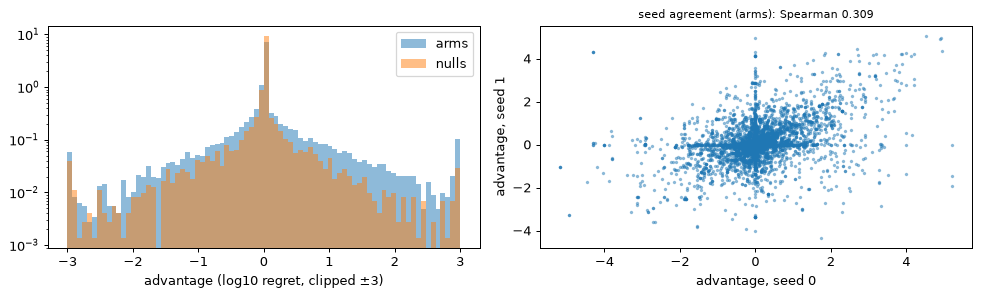

In [ ]:
B["t_bin"] = pd.cut(B.t, [-1, 3, 7, 11, 15])
nb = B[B.option != "base"].copy()
nb["family"] = np.where(nb.arm.str.startswith("ei@"), "nulls", "arms")
print("mean advantage by branch step and k (arms vs nulls):")
display(nb.pivot_table(index="t_bin", columns=["family", "k"], values="adv", aggfunc="mean", observed=True).round(4))
print("share of lanes whose advantage is exactly 0:")
display(nb.assign(zero=nb.adv.abs() < 1e-12).pivot_table(index="k", columns="family", values="zero", aggfunc="mean").round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), dpi=90)
for f, g in nb.groupby("family"):
    ax[0].hist(np.clip(g.adv, -3, 3), bins=80, alpha=.5, label=f, density=True)
ax[0].set_yscale("log"); ax[0].set_xlabel("advantage (log10 regret, clipped ±3)"); ax[0].legend()
a = nb[nb.family == "arms"].pivot_table(index=["state", "option"], columns="rep", values="adv")
ax[1].scatter(a[0], a[1], s=3, alpha=.4); ax[1].set_xlabel("advantage, seed 0"); ax[1].set_ylabel("advantage, seed 1")
ax[1].set_title(f"seed agreement (arms): Spearman {a[0].corr(a[1], method='spearman'):.3f}", fontsize=9)
plt.tight_layout(); plt.show()

### Robustness: the floor ε (revision after the sanity run)

Headroom recomputed from the raw regrets with ε = 1e-5 (the run uses ε = 1e-6).

In [ ]:
h5, _ = crossfit_table(with_eps(B, 1e-5), sorted(B.k[B.k > 0].unique()), 2000)
display(h5[["k", "family", "H", "lo", "hi"]].round(4))
print("share of Part B regrets below 1e-6 / 1e-5:", (B.regret_bins * 1e-3 < 1e-6).mean().round(3), (B.regret_bins * 1e-3 < 1e-5).mean().round(3))

,k,family,H,lo,hi
0,1,static,0.0249,-0.0029,0.0530
1,1,arms-static,0.0621,0.0383,0.0875
2,1,arms,0.0870,0.0623,0.1163
3,1,nulls,-0.0129,-0.0236,-0.0031
4,1,arms-nulls,0.0999,0.0731,0.1288
5,3,static,0.0720,0.0375,0.1085
6,3,arms-static,0.0752,0.0442,0.1083
7,3,arms,0.1472,0.1092,0.1863
8,3,nulls,-0.0037,-0.0184,0.0113
9,3,arms-nulls,0.1508,0.1117,0.1905


share of Part B regrets below 1e-6 / 1e-5: 0.386 0.533


In [ ]:
# Post hoc (not pre-registered): headroom by task type. A task is effectively 1-D when one of its two inputs is irrelevant.
from anytime_acq.analysis.options import crossfit_per_state, static_per_state
from anytime_acq.bo.tasks import draw_tasks
from anytime_acq.analysis.stats import bootstrap_ci
st_seed = B.groupby("state").seed.first()
tk = draw_tasks(2, [int(s) for s in st_seed], n_dense=16, n_refine=1, refine_steps=1)
nrel = pd.Series(tk.prior.relevant_mask.sum(1).numpy(), index=st_seed.index)
rows = []
for k in (1, 3, 5):
    H, S_ = crossfit_per_state(B, k, "arms").H, static_per_state(B, k)
    for lab, m in (("1-D", nrel == 1), ("2-D", nrel == 2)):
        for name, v in (("arms", H[m.to_numpy()]), ("static", S_[m.to_numpy()]), ("arms-static", (H - S_)[m.to_numpy()])):
            lo, hi = bootstrap_ci(v.to_numpy(), n_boot=2000)
            rows.append({"k": k, "tasks": lab, "n": int(m.sum()), "quantity": name, "H": v.mean(), "lo": lo, "hi": hi})
display(pd.DataFrame(rows).pivot_table(index=["k", "quantity"], columns="tasks", values=["H", "lo", "hi"]).round(3))

H            hi            lo       
tasks            1-D    2-D    1-D    2-D    1-D    2-D
k quantity                                             
1 arms         0.100  0.134  0.145  0.189  0.058  0.082
  arms-static  0.056  0.129  0.094  0.177  0.022  0.080
  static       0.044  0.005  0.077  0.056  0.011 -0.048
3 arms         0.159  0.234  0.220  0.308  0.098  0.164
  arms-static  0.068  0.152  0.113  0.218  0.026  0.087
  static       0.091  0.082  0.147  0.152  0.036  0.017
5 arms         0.197  0.330  0.262  0.413  0.129  0.256
  arms-static  0.112  0.182  0.162  0.246  0.061  0.118
  static       0.085  0.148  0.138  0.226  0.035  0.070

## Observations (pilot, snapshot `results/option_headroom/pilot_20261112-111235`)

Written after the run. Advantages are in log10 terminal regret; positive = better than EI; ε = 1e-6.
- **There is a luck-corrected, non-zero advantage over EI: the first one in this line of work.**
  - Arms' cross-fitted headroom: H₁ = 0.116 [0.086, 0.153], **H₃ = 0.195 [0.148, 0.244]**, H₅ = 0.262 [0.212, 0.313].
  - H₃ = 0.195 log10 means about 36% less regret (10^−0.195 = 0.64).
  - The nulls (EI on a random half of the candidates) are at ≈ 0 (H₃ −0.007 [−0.026, 0.013]), so this is not luck of the candidate set.
  - **Verdict: GO.**
- **About half of it is context-dependent.**
  - The best *single* option (always switch to it) gives H₃,static = 0.086 [0.043, 0.134].
  - The context-dependent part, arms − static, is **0.109 [0.070, 0.150]**, with H₁ 0.092 and H₅ 0.146, all CIs > 0.
  - Choosing *which* arm per state adds as much as switching at all.
- **Robust to the floor:** at ε = 1e-5, H₃ = 0.147 [0.109, 0.186] and the context part 0.075 [0.044, 0.108]. 39% / 53% of Part B regrets are below 1e-6 / 1e-5.
- **Static arms (Part A, 500 split-0 tasks) under log regret:** EI is *not* the best static arm.
  - Mean final log10 regret: MES −4.67, UCB(0.995) −4.64, EI −4.48, PI(0.01) −4.04, mean −3.57.
  - Median: UCB −5.29, MES −5.21, EI −4.96.
  - This matches static_tune's B\* = MES at d = 2.
- **By task type** (post hoc): the context-dependent part is larger on 2-D tasks than on effectively 1-D tasks.
  - k = 3: 0.152 [0.087, 0.218] vs 0.068 [0.026, 0.113].
  - k = 5: 0.182 vs 0.112.
- **By option:**
  - Longer options gain more: UCB 0.033 → 0.074 → 0.125 and MES 0.029 → 0.065 → 0.116 for k = 1, 3, 5.
  - Pure exploitation (`mean`) is ≈ 0 to slightly negative on average, but contributes to the per-state choice.
  - Options disagree with EI's first pick in 79–88% of states; nulls in about 50%.
- **Basins: at d = 2 the gain is mostly not basin discovery.**
  - Net basin gain (option ends in a good basin and EI does not, minus the reverse) is at most +0.034 (UCB k = 5, δ = 1 bin).
  - The median time to a good basin is 0 for every arm: the best initial point usually already drains to the global basin.
  - The difference between good-basin and not-good runs is about 3 decades, but it affects only 8–15% of runs per arm.
  - So most of the advantage is **polishing efficiency** in log terms. Basin discovery matters in the rugged 2-D minority. Scratch check on 500 split-0 tasks: 2-D tasks have a median of 12 distinct local minima, and 11% have ≥ 20.
- **Belief after the option:** P(y(x\*) < incumbent) is slightly higher after arms than after nulls at k = 5 (0.47–0.48 vs 0.45), and the predicted-minimum location is slightly closer to x\* (0.26–0.27 vs 0.28). Small effects; not tested.
- **Luck scale:** seed-to-seed |Δ log10 regret| of the same arm on the same task is median 0.14–0.24 and mean 0.39–0.55. Single-replicate comparisons are therefore very noisy. Cross-fitting over seeds is what makes the headroom credible.
- **Limits of the reading.** The headroom is **privileged**: an option is selected on outcomes of the same task under another candidate set. It is an upper bound for a policy that sees only the belief. Whether the belief predicts which option wins (and the static part, which needs no prediction) is the next question.


## Verdict

In [ ]:
k = 3
print("verdict (analysis/options.py::option_verdict, arms' H at k = 3):", option_verdict(head, k, 0.022))

verdict (analysis/options.py::option_verdict, arms' H at k = 3): GO


## Addendum: the d = 4 sweep (analysis pre-stated in the addendum to the description)


In [ ]:
snap4 = load_snapshot("results/option_headroom/pilot_20261114-105056")
show_header(snap4)
print("member status:", snap4.runs.status.value_counts().to_dict())
A4, B4, head4, arms4 = (snap4.table(k) for k in ("part_a", "part_b", "headroom", "arms_b"))
def along(A_):
    A_ = A_.assign(reg=A_.regret_bins * 1e-3, good1=A_.basin_gap_bins <= 1); T_ = A_.t.max(); out = []
    for tt in (T_ // 4, T_ // 2, T_):
        g = A_[A_.t == tt]
        r = g.groupby("arm").agg(above_1e3=("reg", lambda x: (x > 1e-3).mean()), above_1e2=("reg", lambda x: (x > 1e-2).mean()), good_basin=("good1", "mean"))
        r["mean_log_regret_floor_1e3"] = np.log10(g.reg + 1e-3).groupby(g.arm).mean()
        out.append(r.assign(t=tt))
    tau = A_[A_.good1].groupby(["task", "arm", "rep"]).t.min()
    reach = pd.DataFrame({"median": tau.groupby("arm").median(), "q75": tau.groupby("arm").quantile(.75),
                          "share_reached": tau.groupby("arm").size() / A_.groupby(["task", "arm", "rep"]).ngroups * A_.arm.nunique()})
    return pd.concat(out).reset_index().set_index(["t", "arm"]).round(3), reach.round(3)
for name, A_ in (("d = 2 (T = 20)", A), ("d = 4 (T = 40)", A4)):
    tab_, reach = along(A_)
    print(name, ": Part A along the run (both seeds pooled)"); display(tab_)
    print(name, ": first step in a good basin (delta = 1 bin), over runs that reach one; share of runs that ever do"); display(reach)
print("d = 4: headroom (eps = 1e-6, as pre-registered)"); display(head4[["k", "family", "H", "lo", "hi", "oracle", "deviates"]].round(3))
h4, _ = crossfit_table(with_eps(B4, 1e-3), sorted(B4.k[B4.k > 0].unique()), 2000)
h2, _ = crossfit_table(with_eps(B, 1e-3), sorted(B.k[B.k > 0].unique()), 2000)
print("headroom at eps = 1e-3, d = 2 and d = 4:"); display(h2[["k", "family", "H", "lo", "hi"]].merge(h4[["k", "family", "H", "lo", "hi"]], on=["k", "family"], suffixes=(" d2", " d4")).round(3))
print("d = 4: options"); display(arms4[["option", "adv_mean", "lo", "hi", "share_pos", "share_neg", "basin_gain_1", "basin_gain_10"]].round(3))
print("d = 4 verdict (same rule, arms' H at k = 3):", option_verdict(head4, 3, 0.022))


## How it was run

```bash
just sweep detached pilot experiment=option_headroom task.d=4 task.part_b.t_max=30
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261114-105056` |
| commit | `9c091abb2afb` (tag `sweep/option_headroom/pilot_20261114-105056`) |
| backend / host | detached / ulysses |
| ran | 2026-11-14T10:50:58 → 2026-11-14T11:30:47 |
| members | 1: 1 done |
| compute | 39.8 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/option_headroom.yaml`):

```yaml
# @package _global_
# Basin decomposition of static arms and exact, luck-corrected option labels (issue #13, decision 0008).
# Pre-registration: notebooks/12_2026-11-12_option_headroom.ipynb.
defaults:
  - override /task: option_headroom

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  arms: '["ei", "pi0.01", "ucb0.995", "mes", "mean"]'
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 4
  deltas: '[1, 10]'
  descent.check_lr: 0.001
  descent.check_steps: 600
  descent.chunk: 65536
  descent.lr: 0.003
  descent.steps: 300
  device: cuda
  eps: 1.0e-06
  ks: '[1, 3, 5]'
  n_boot: 2000
  n_init_per_d: 2
  n_null: 2
  name: option_headroom
  part_a.n_tasks: 500
  part_a.split: 0
  part_a.task_offset: 0
  part_b.n_tasks: 800
  part_b.split: 4
  part_b.t_max: 30
  part_b.task_offset: 20000
  pfn: pfn_large
  primary_k: 3
  seeds: '[0, 1]'
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  tf32: false
  worthwhile_log10: 0.022
```

member status: {'DONE': 1}


d = 2 (T = 20) : Part A along the run (both seeds pooled)


above_1e3  above_1e2  good_basin  mean_log_regret_floor_1e3
t  arm                                                                  
5  ei            0.502      0.277       0.748                     -2.359
   mean          0.622      0.426       0.677                     -2.124
   mes           0.638      0.351       0.785                     -2.193
   pi0.01        0.561      0.293       0.744                     -2.291
   ucb0.995      0.638      0.348       0.808                     -2.210
10 ei            0.324      0.156       0.818                     -2.618
   mean          0.525      0.336       0.683                     -2.285
   mes           0.367      0.180       0.854                     -2.566
   pi0.01        0.383      0.163       0.834                     -2.550
   ucb0.995      0.401      0.184       0.871                     -2.546
20 ei            0.211      0.088       0.854                     -2.763
   mean          0.437      0.290       0.688                     -2.377
   mes           0.159      0.071       0.924                     -2.815
   pi0.01        0.274      0.076       0.898                     -2.721
   ucb0.995      0.194      0.072       0.925                     -2.801

d = 2 (T = 20) : first step in a good basin (delta = 1 bin), over runs that reach one; share of runs that ever do


,median,q75,share_reached
arm,,,
ei,0.0,0.0,0.874
mean,0.0,0.0,0.717
mes,0.0,1.0,0.945
pi0.01,0.0,1.0,0.911
ucb0.995,0.0,1.0,0.951


... (7 outputs left out)

,k,family,H d2,lo d2,hi d2,H d4,lo d4,hi d4
0,1,static,0.009,-0.001,0.019,-0.001,-0.008,0.007
1,1,arms-static,0.014,0.006,0.024,0.006,-0.006,0.017
2,1,arms,0.024,0.013,0.036,0.005,-0.008,0.018
3,1,nulls,-0.004,-0.007,-0.001,0.002,-0.003,0.008
4,1,arms-nulls,0.028,0.017,0.040,0.003,-0.010,0.015
5,3,static,0.020,0.007,0.034,0.016,0.001,0.030
6,3,arms-static,0.023,0.012,0.035,-0.000,-0.011,0.010
7,3,arms,0.043,0.027,0.060,0.016,0.002,0.030
8,3,nulls,-0.001,-0.006,0.005,-0.008,-0.017,0.000
9,3,arms-nulls,0.044,0.027,0.061,0.024,0.010,0.038


d = 4: options


,option,adv_mean,lo,hi,share_pos,share_neg,basin_gain_1,basin_gain_10
0,mean_k1,-0.020,-0.043,0.003,0.246,0.261,-0.011,-0.009
1,mean_k3,-0.013,-0.040,0.014,0.319,0.291,-0.009,-0.011
2,mean_k5,-0.046,-0.076,-0.015,0.326,0.331,-0.014,-0.015
3,mes_k1,-0.010,-0.037,0.017,0.258,0.267,-0.003,-0.008
4,mes_k3,0.034,0.002,0.067,0.331,0.306,0.001,-0.004
5,mes_k5,0.084,0.049,0.119,0.374,0.301,0.021,0.017
6,null0_k1,-0.017,-0.034,-0.000,0.119,0.121,-0.001,-0.008
7,null0_k3,-0.018,-0.043,0.006,0.231,0.216,-0.006,-0.011
8,null0_k5,-0.009,-0.035,0.016,0.284,0.250,-0.004,-0.009
9,null1_k1,-0.013,-0.031,0.005,0.131,0.123,0.001,-0.001


d = 4 verdict (same rule, arms' H at k = 3): GO


### Observations, d = 4 (2026-11-14; snapshot `results/option_headroom/pilot_20261114-105056`, 1 member, DONE)

Numbers from the cell above. Part A: 500 split-0 tasks, 2 seeds, T = 40. Part B: 800 states.

- **d = 4 is the harder regime, but not a different one.**
  - EI ends above one PFN bin (1e-3) in 44% of runs (d = 2: 21%) and above 1e-2 in 17% (9%).
  - EI ends in a good basin (within 1 bin of f\*) in 72% of runs (d = 2: 85%); UCB in 81% (93%). About a quarter of EI's runs never reach one (24%; d = 2: 13%).
  - For the runs that do, the median first step in a good basin is still 0 for every arm: the initial design is already there. The 75% quantile is 1–4 steps.
- **Which arm is best depends on the budget.** Mean log10(regret + 1e-3): at T/4 EI is best (−2.216; UCB −2.122), at T/2 MES (−2.471; EI −2.433), at T UCB (−2.685; MES −2.663; EI −2.552). UCB over EI at T: 0.13.
- **The option headroom is smaller than at d = 2 and entirely static.** H₃ of the arms: 0.076 [0.039, 0.112] (d = 2: 0.195 [0.148, 0.244]). Static part 0.059 [0.022, 0.096]; context-dependent part (arms − static) **0.017 [−0.013, 0.049]** (d = 2: 0.109 [0.070, 0.150]). At k = 5: 0.101, static 0.080, context 0.021 [−0.012, 0.053].
- **At ε = 1e-3 almost nothing is left**: H₃ 0.016 [0.002, 0.030], context part −0.000 [−0.011, 0.010]; at k = 5 the context part is negative (−0.014 [−0.027, −0.002]).
- **Options rarely change the basin**: net basin gain at most +0.022 (UCB or MES for 5 steps), as at d = 2.
- Verdict by the pre-registered rule (arms' H at k = 3): GO, as at d = 2; but what is there at d = 4 is one fixed deviation ("UCB or MES for some steps"), not a state-dependent choice.

Reading: the harder regime raises the share of runs that fail (wrong basin, 1 in 4 for EI) without making short deviations more valuable. The gain over EI at d = 4 is in the arm used for long stretches of the budget (UCB late, EI early), which is a budget schedule.
